In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

100%|██████████| 13.1M/13.1M [00:00<00:00, 192MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/banksim1/versions/1


In [5]:
plt.style.use('seaborn-v0_8')
colors_basketball = ['#F57E00', '#FFA90A', '#FFCE72', '#3AAFF9', '#0087DC', '#005991']
colors_60s = ['#BF4402', '#94058E', '#005DD7', '#2690C3', '#F5C402', '#CE378E']

In [ ]:
# plt.rcParams['figure.facecolor'] = '#F8F8F8' # Replaced 'grey97' with '#F8F8F8'
# plt.rcParams['axes.facecolor'] = '#F8F8F8'   # Replaced 'grey97' with '#F8F8F8'
# plt.rcParams['axes.grid'] = True
# plt.rcParams['grid.color'] = '#DCDCDC'   # Replaced 'grey87' with '#DCDCDC'
# plt.rcParams['text.color'] = 'grey25'
# plt.rcParams['axes.labelcolor'] = 'grey25'
# plt.rcParams['xtick.color'] = 'grey25'
# plt.rcParams['ytick.color'] = 'grey25'

In [8]:
data = pd.read_csv(path+'/bs140513_032310.csv')

In [9]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)

In [10]:
data['customer'] = data['customer'].str.strip("'")
data['age'] = data['age'].str.strip("'")
data['gender'] = data['gender'].str.strip("'")
data['merchant'] = data['merchant'].str.strip("'")
data['category'] = data['category'].str.strip("'")

In [11]:
data['category'] = data['category'].str.replace('es_', '')

In [12]:
data = data[data['gender'] != 'U']

In [13]:
data['age'] = data['age'].replace('U', '7')

In [14]:
def amount_threshold(amount):
    if amount <= 500:
        return '0-500'
    elif amount <= 1000:
        return '500-1000'
    elif amount <= 1500:
        return '1000-1500'
    elif amount <= 2000:
        return '1500-2000'
    elif amount <= 2500:
        return '2000-2500'
    elif amount <= 3000:
        return '2500-3000'
    else:
        return '>3000'

In [15]:
data['amount_thresh'] = data['amount'].apply(amount_threshold)

In [16]:
print(data.head())

   step     customer age gender     merchant        category  amount  fraud  \
0     0  C1093826151   4      M   M348934600  transportation    4.55      0   
1     0   C352968107   2      M   M348934600  transportation   39.68      0   
2     0  C2054744914   4      F  M1823072687  transportation   26.89      0   
3     0  C1760612790   3      M   M348934600  transportation   17.25      0   
4     0   C757503768   5      M   M348934600  transportation   35.72      0   

  amount_thresh  
0         0-500  
1         0-500  
2         0-500  
3         0-500  
4         0-500  


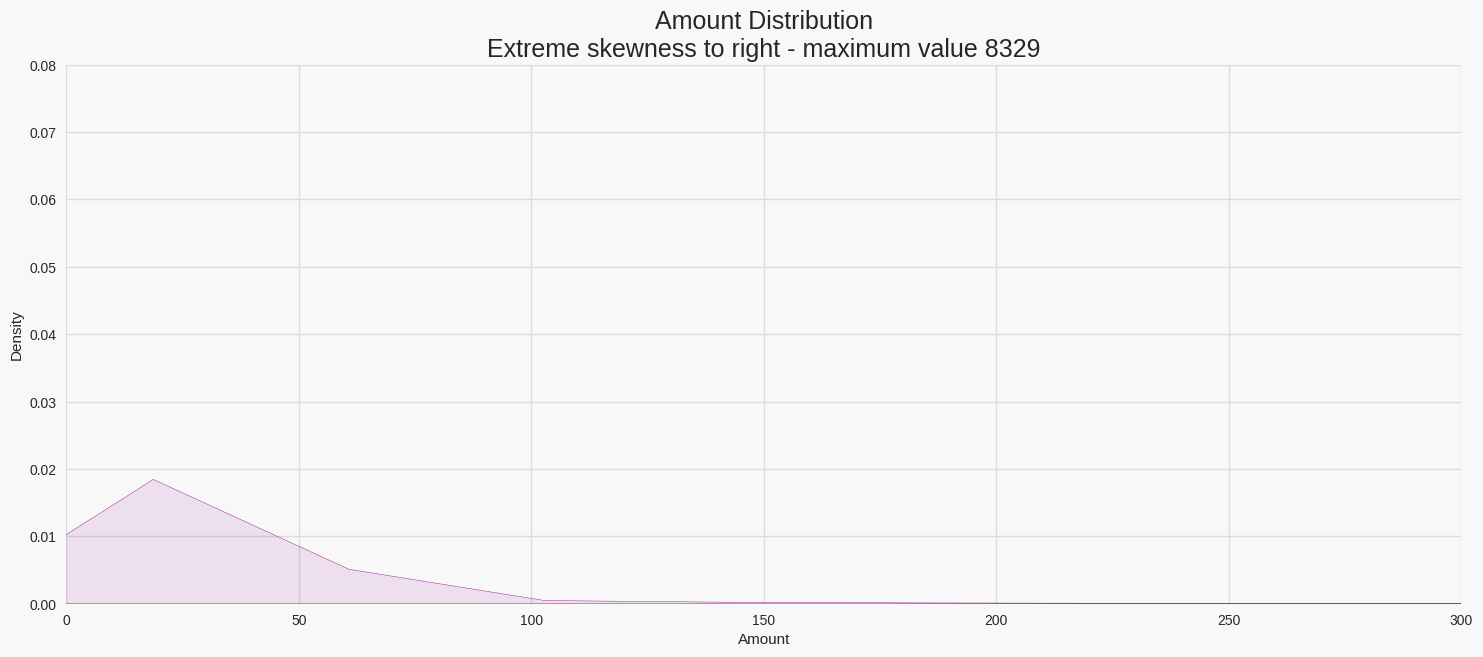

In [17]:
plt.figure(figsize=(18, 7))
sns.kdeplot(data=data, x='amount', color=colors_60s[1], fill=True, alpha=0.1)
plt.xlim(0, 300)
plt.ylim(0, 0.08)
plt.title('Amount Distribution\nExtreme skewness to right - maximum value 8329', fontsize=18)
plt.xlabel('Amount', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.savefig('amount_distribution.png')
plt.show()

In [19]:
gender_spent = data.groupby('gender')['amount'].mean().reset_index()
gender_spent['Metric'] = 'gender'

In [20]:
age_spent = data.groupby('age')['amount'].mean().reset_index()
age_spent['Metric'] = 'age'

In [21]:
category_spent = data.groupby('category')['amount'].mean().reset_index()
category_spent['Metric'] = 'category'

In [22]:
spenders = pd.concat([gender_spent, age_spent, category_spent], ignore_index=True)
spenders['Metric'] = pd.Categorical(spenders['Metric'], categories=['category', 'age', 'gender'])

<Figure size 1800x700 with 0 Axes>

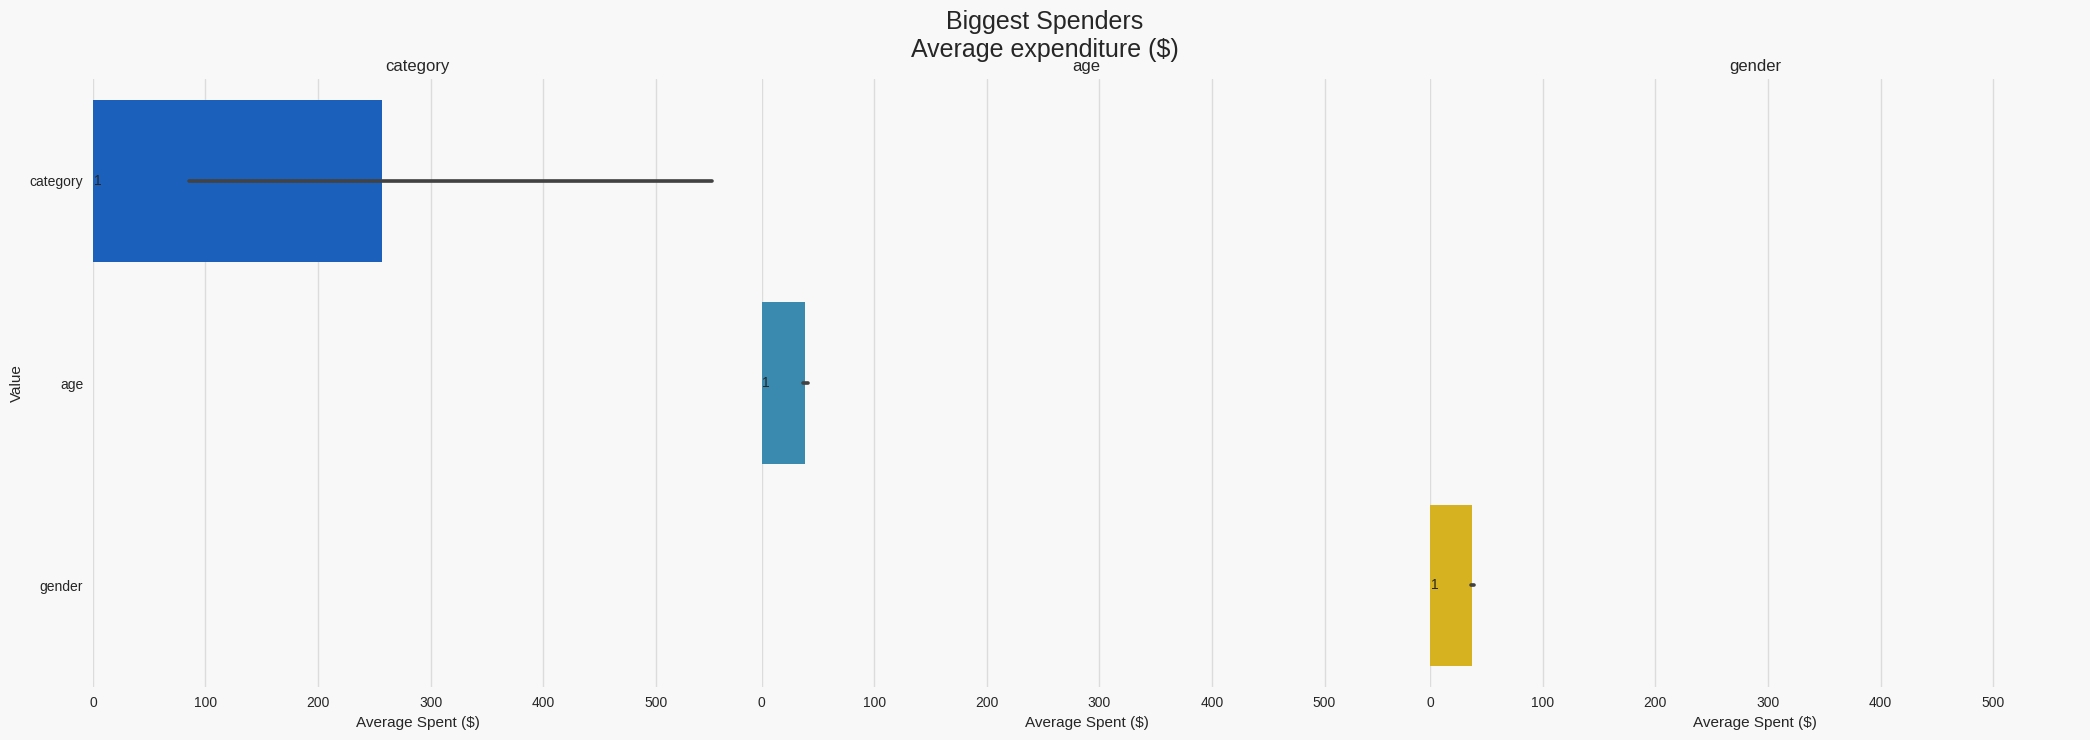

In [23]:
plt.figure(figsize=(18, 7))
g = sns.catplot(data=spenders, x='amount', y='Metric', hue='Metric', col='Metric',
                kind='bar', palette=colors_60s[2:5], height=7, aspect=1, col_wrap=3)
for ax in g.axes.flat:
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(height, bar.get_y() + bar.get_height()/2, f'{height:,.0f}',
                va='center', ha='left', size=10)
    ax.set_title(ax.get_title().replace('Metric = ', ''))
    ax.set_xlabel('Average Spent ($)')
    ax.set_ylabel('Value')
plt.suptitle('Biggest Spenders\nAverage expenditure ($)', fontsize=18, y=1.05)
plt.savefig('biggest_spenders.png')
plt.show()

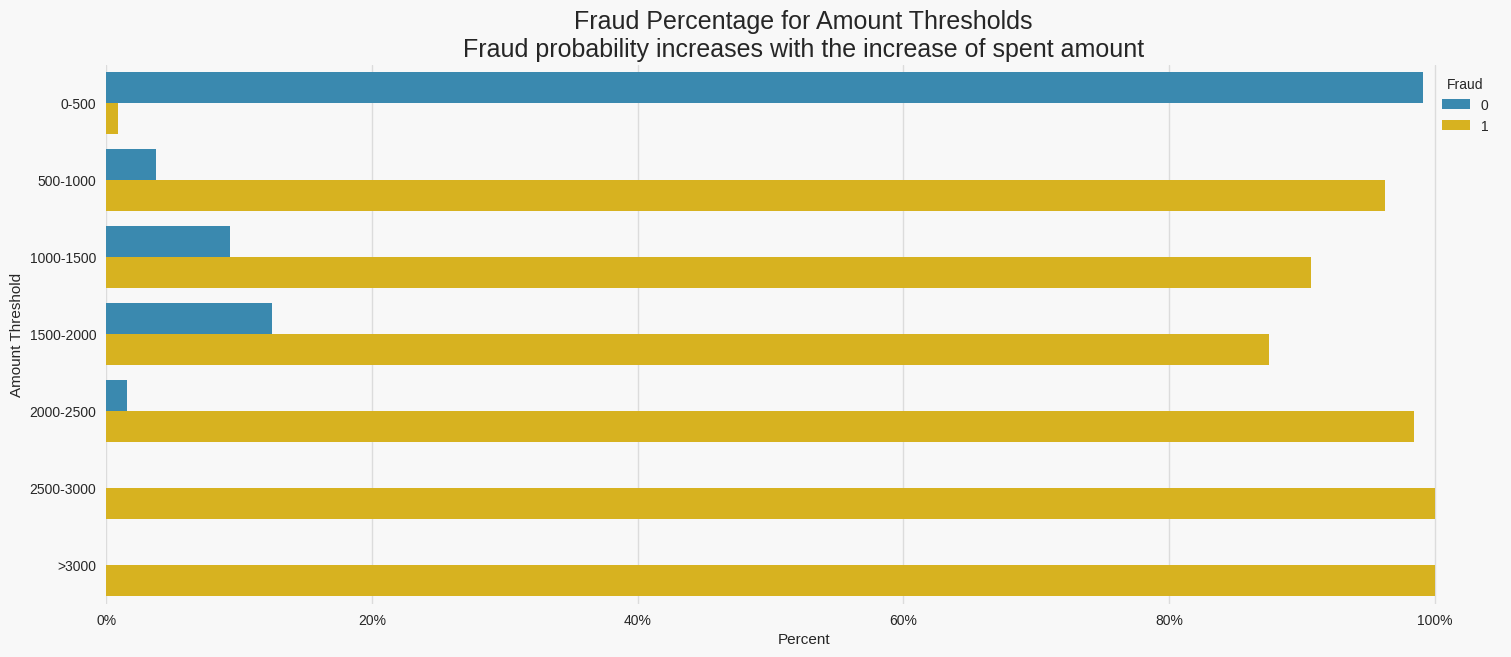

In [24]:
plt.figure(figsize=(18, 7))
amount_fraud = data.groupby(['amount_thresh', 'fraud']).size().unstack(fill_value=0)
amount_fraud = amount_fraud.div(amount_fraud.sum(axis=1), axis=0)
amount_fraud = amount_fraud.reset_index().melt(id_vars='amount_thresh', value_vars=[0, 1], var_name='fraud', value_name='percent')
amount_fraud['amount_thresh'] = pd.Categorical(amount_fraud['amount_thresh'],
                                              categories=['0-500', '500-1000', '1000-1500', '1500-2000', '2000-2500', '2500-3000', '>3000'])
sns.barplot(data=amount_fraud, x='percent', y='amount_thresh', hue='fraud', palette=colors_60s[3:5])
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
plt.title('Fraud Percentage for Amount Thresholds\nFraud probability increases with the increase of spent amount', fontsize=18)
plt.xlabel('Percent')
plt.ylabel('Amount Threshold')
plt.legend(title='Fraud')
plt.savefig('fraud_percentage.png')
plt.show()

<Figure size 1800x700 with 0 Axes>

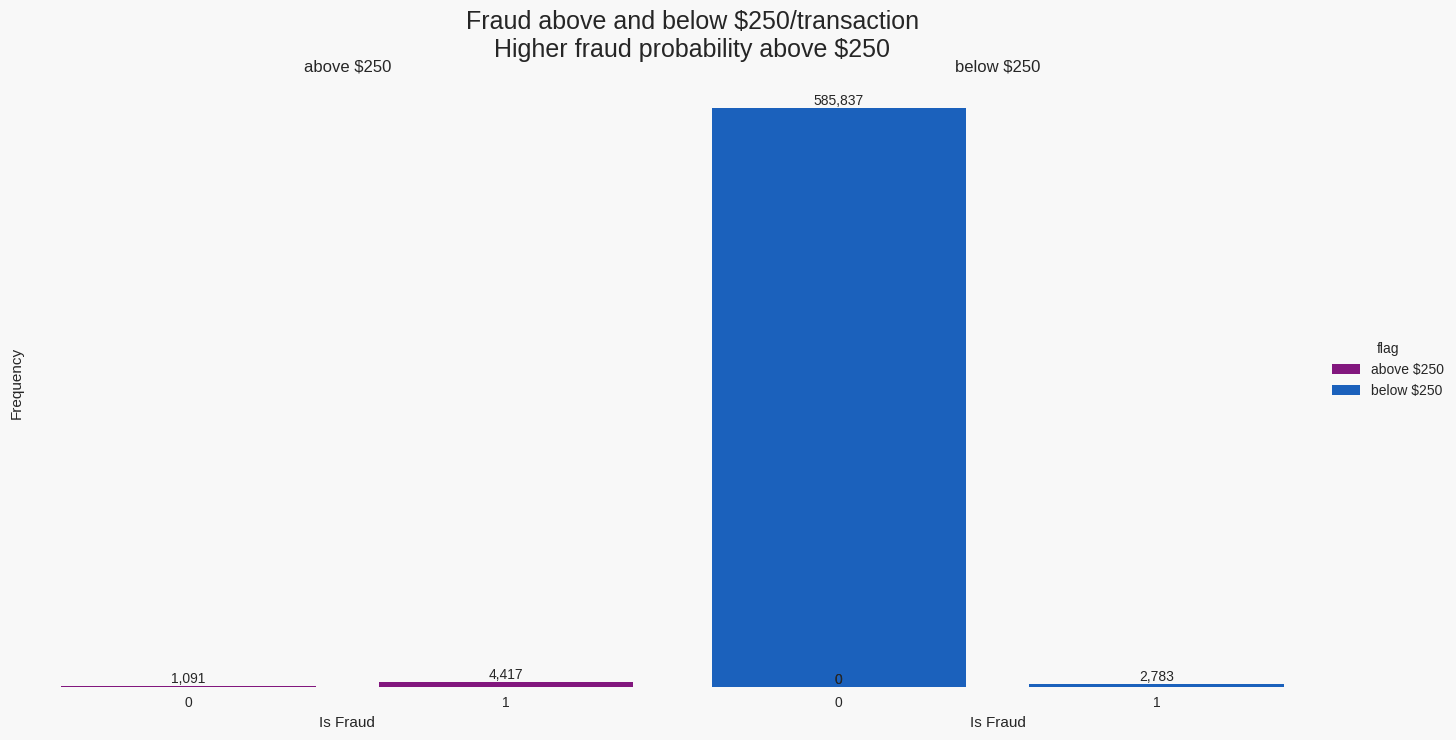

In [25]:
data['flag'] = data['amount'].apply(lambda x: 'below $250' if x <= 250 else 'above $250')
plt.figure(figsize=(18, 7))
g = sns.catplot(data=data.groupby(['fraud', 'flag']).size().reset_index(name='n'),
                x='fraud', y='n', hue='flag', col='flag', kind='bar',
                palette=colors_60s[1:3], height=7, aspect=1)
for ax in g.axes.flat:
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}',
                ha='center', va='bottom', size=10)
    ax.set_title(ax.get_title().replace('flag = ', ''))
    ax.set_xlabel('Is Fraud')
    ax.set_ylabel('Frequency')
    ax.set_yticks([])
plt.suptitle('Fraud above and below $250/transaction\nHigher fraud probability above $250', fontsize=18, y=1.05)
plt.savefig('fraud_above_below_250.png')
plt.show()

In [26]:
outliers = data[data['amount'] > 500]

In [27]:
gender_outliers = outliers.groupby('gender').size().reset_index(name='n')
gender_outliers['Metric'] = 'gender'

In [28]:
age_outliers = outliers.groupby('age').size().reset_index(name='n')
age_outliers['Metric'] = 'age'

In [29]:
category_outliers = outliers.groupby('category').size().reset_index(name='n')
category_outliers['Metric'] = 'category'

In [30]:
outliers_combined = pd.concat([gender_outliers, age_outliers, category_outliers], ignore_index=True)
outliers_combined['Metric'] = pd.Categorical(outliers_combined['Metric'], categories=['category', 'age', 'gender'])

<Figure size 1800x700 with 0 Axes>

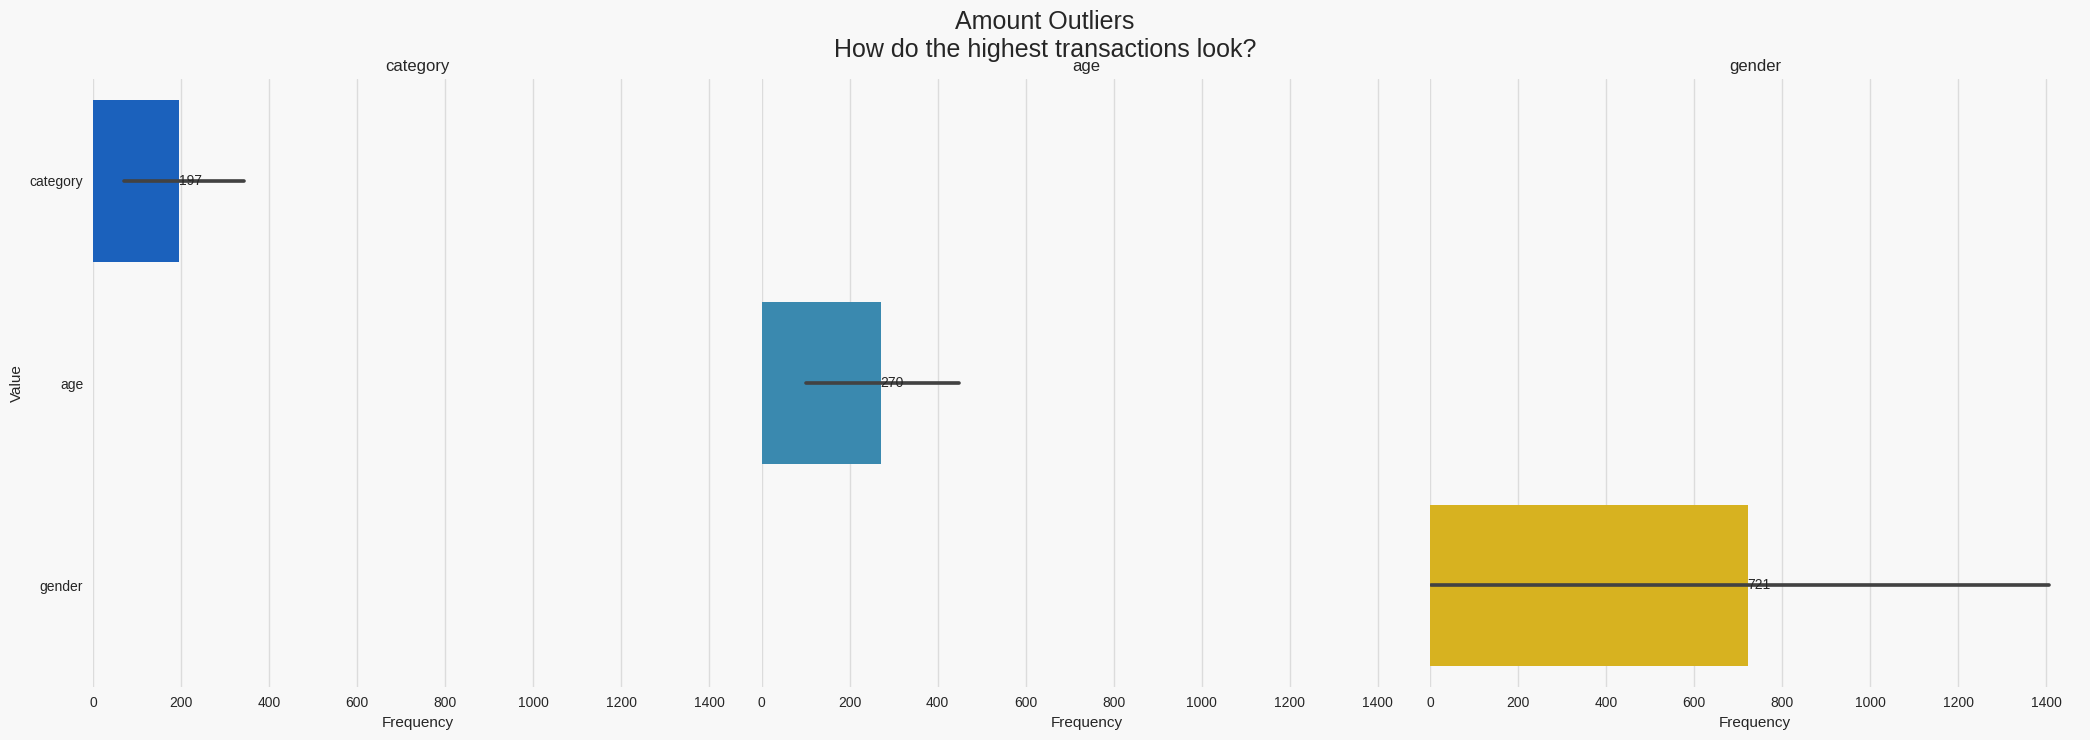

In [31]:
plt.figure(figsize=(18, 7))
g = sns.catplot(data=outliers_combined, x='n', y='Metric', hue='Metric', col='Metric',
                kind='bar', palette=colors_60s[2:5], height=7, aspect=1, col_wrap=3)
for ax in g.axes.flat:
    for i, bar in enumerate(ax.patches):
        width = bar.get_width()
        ax.text(width, bar.get_y() + bar.get_height()/2, f'{width:,.0f}',
                va='center', ha='left', size=10)
    ax.set_title(ax.get_title().replace('Metric = ', ''))
    ax.set_xlabel('Frequency')
    ax.set_ylabel('Value')
plt.suptitle('Amount Outliers\nHow do the highest transactions look?', fontsize=18, y=1.05)
plt.savefig('outliers_amount.png')
plt.show()

/tmp/ipython-input-33-777907968.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


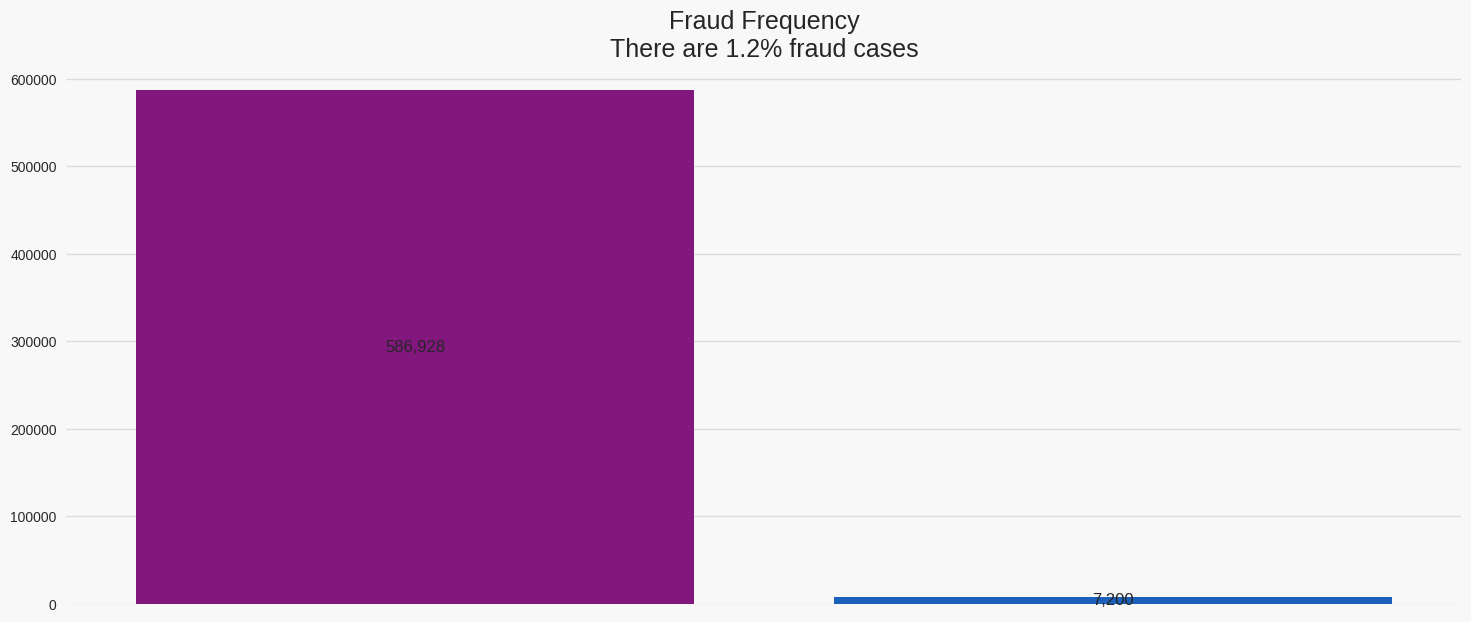

In [33]:
plt.figure(figsize=(18, 7))
fraud_counts = data['fraud'].value_counts().reset_index(name='n')
fraud_counts['fraud'] = fraud_counts['fraud'].astype(str)
sns.barplot(data=fraud_counts, x='fraud', y='n', hue='fraud', palette=colors_60s[1:3])
for i, bar in enumerate(plt.gca().patches):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height/2, f'{height:,.0f}',
             ha='center', va='center', size=12)
plt.title('Fraud Frequency\nThere are 1.2% fraud cases', fontsize=18)
plt.xlabel('')
plt.ylabel('')
plt.xticks([])
plt.legend().remove()
plt.savefig('fraud_frequency.png')
plt.show()

<Figure size 1800x700 with 0 Axes>

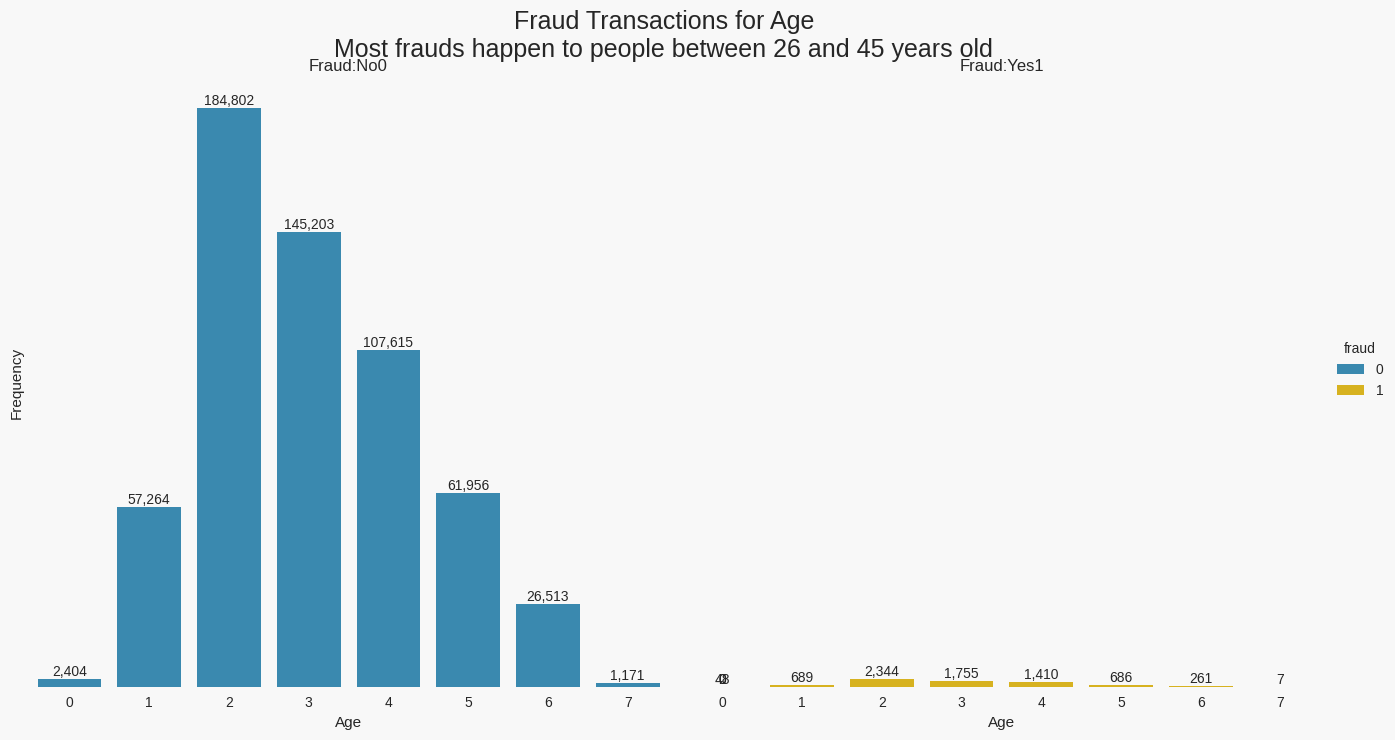

In [34]:
plt.figure(figsize=(18, 7))
g = sns.catplot(data=data.groupby(['age', 'fraud']).size().reset_index(name='n'),
                x='age', y='n', hue='fraud', col='fraud', kind='bar',
                palette=colors_60s[3:5], height=7, aspect=1)
for ax in g.axes.flat:
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}',
                ha='center', va='bottom', size=10)
    ax.set_title(ax.get_title().replace('fraud = ', 'Fraud:{}'.format('Yes' if ax.get_title().endswith('1') else 'No')))
    ax.set_xlabel('Age')
    ax.set_ylabel('Frequency')
    ax.set_yticks([])
plt.suptitle('Fraud Transactions for Age\nMost frauds happen to people between 26 and 45 years old', fontsize=18, y=1.05)
plt.savefig('fraud_transactions_in_age.png')
plt.show()

/tmp/ipython-input-35-1532921426.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_freq, x='n', y='category', palette=colors_60s[4:6])
/tmp/ipython-input-35-1532921426.py:3: UserWarning: 
The palette list has fewer values (2) than needed (14) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=cat_freq, x='n', y='category', palette=colors_60s[4:6])


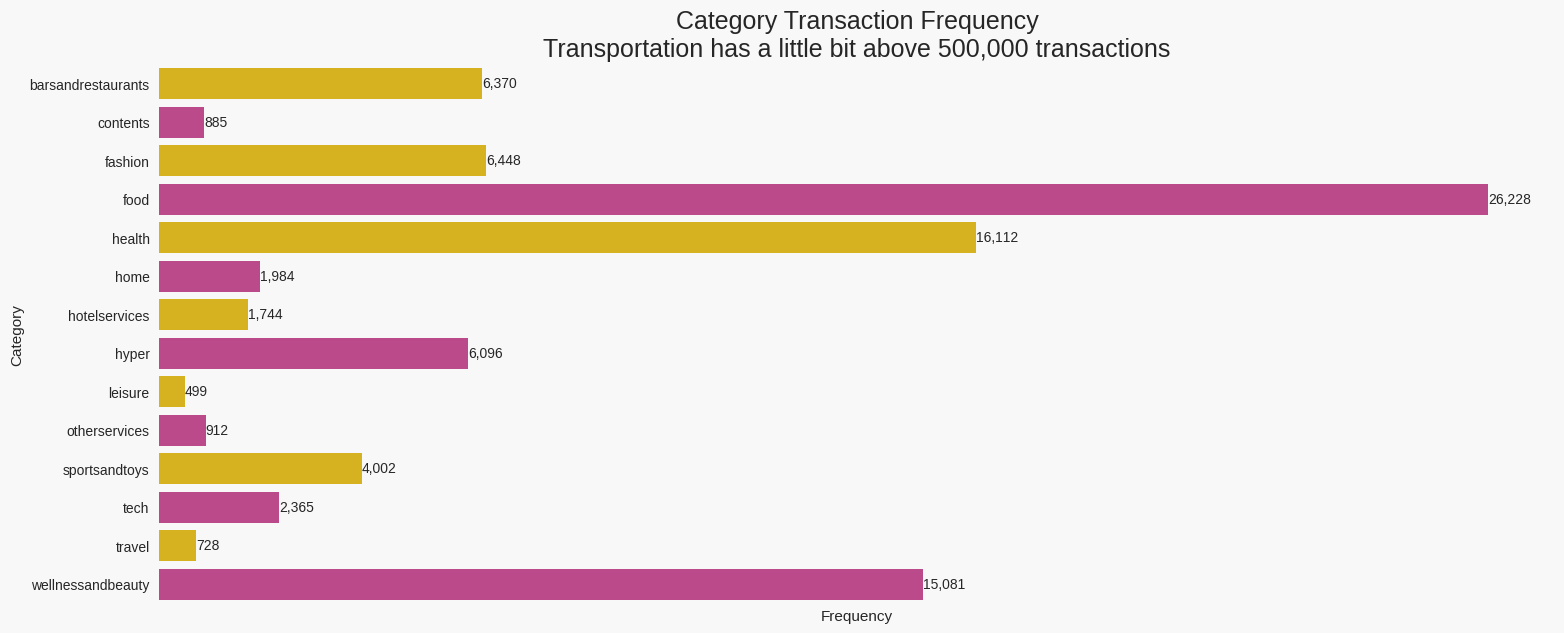

In [35]:
plt.figure(figsize=(18, 7))
cat_freq = data[data['category'] != 'transportation'].groupby('category').size().reset_index(name='n')
sns.barplot(data=cat_freq, x='n', y='category', palette=colors_60s[4:6])
for i, bar in enumerate(plt.gca().patches):
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2, f'{width:,.0f}',
             va='center', ha='left', size=10)
plt.title('Category Transaction Frequency\nTransportation has a little bit above 500,000 transactions', fontsize=18)
plt.xlabel('Frequency')
plt.ylabel('Category')
plt.xticks([])
plt.savefig('categories_transaction_frequency.png')
plt.show()

/tmp/ipython-input-36-1722278247.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fraud_cat, x='n', y='category', palette=colors_60s[4:2:-1])
/tmp/ipython-input-36-1722278247.py:3: UserWarning: 
The palette list has fewer values (2) than needed (12) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=fraud_cat, x='n', y='category', palette=colors_60s[4:2:-1])


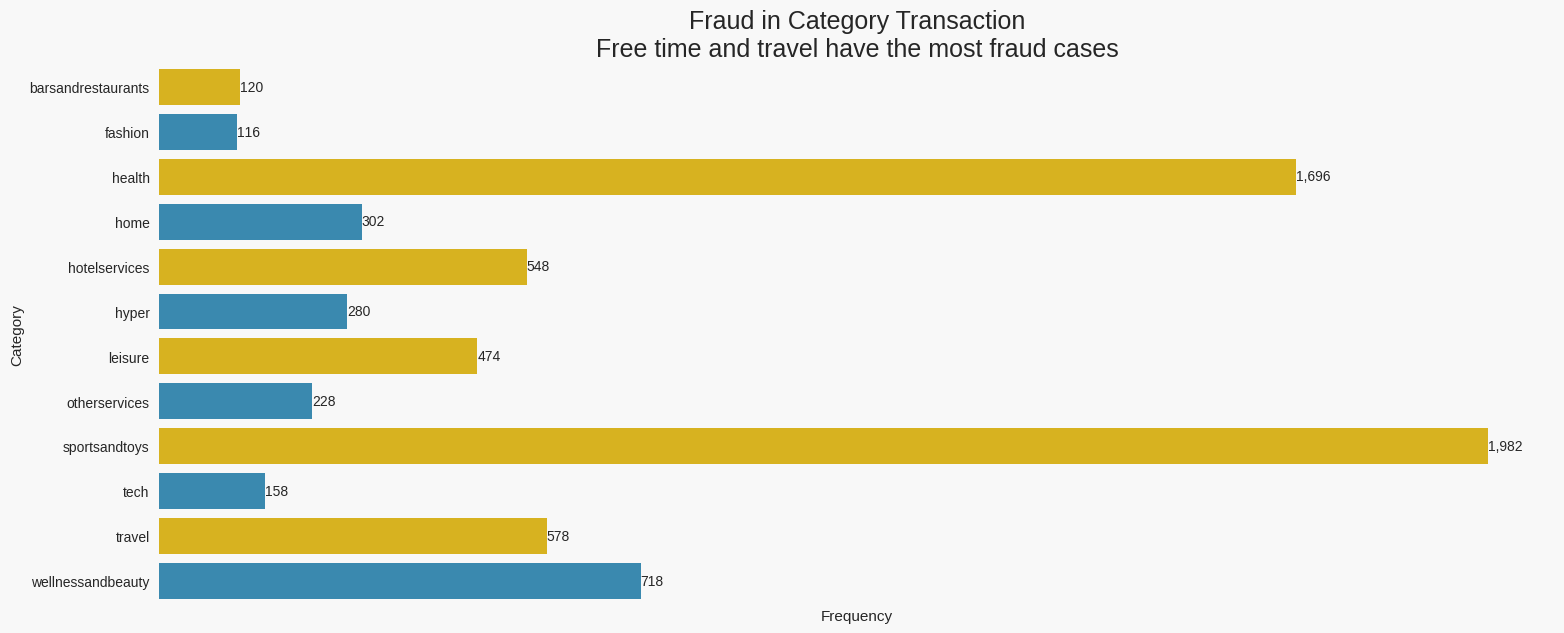

In [36]:
plt.figure(figsize=(18, 7))
fraud_cat = data[data['fraud'] == 1].groupby('category').size().reset_index(name='n')
sns.barplot(data=fraud_cat, x='n', y='category', palette=colors_60s[4:2:-1])
for i, bar in enumerate(plt.gca().patches):
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2, f'{width:,.0f}',
             va='center', ha='left', size=10)
plt.title('Fraud in Category Transaction\nFree time and travel have the most fraud cases', fontsize=18)
plt.xlabel('Frequency')
plt.ylabel('Category')
plt.xticks([])
plt.savefig('fraud_in_category_transaction.png')
plt.show()

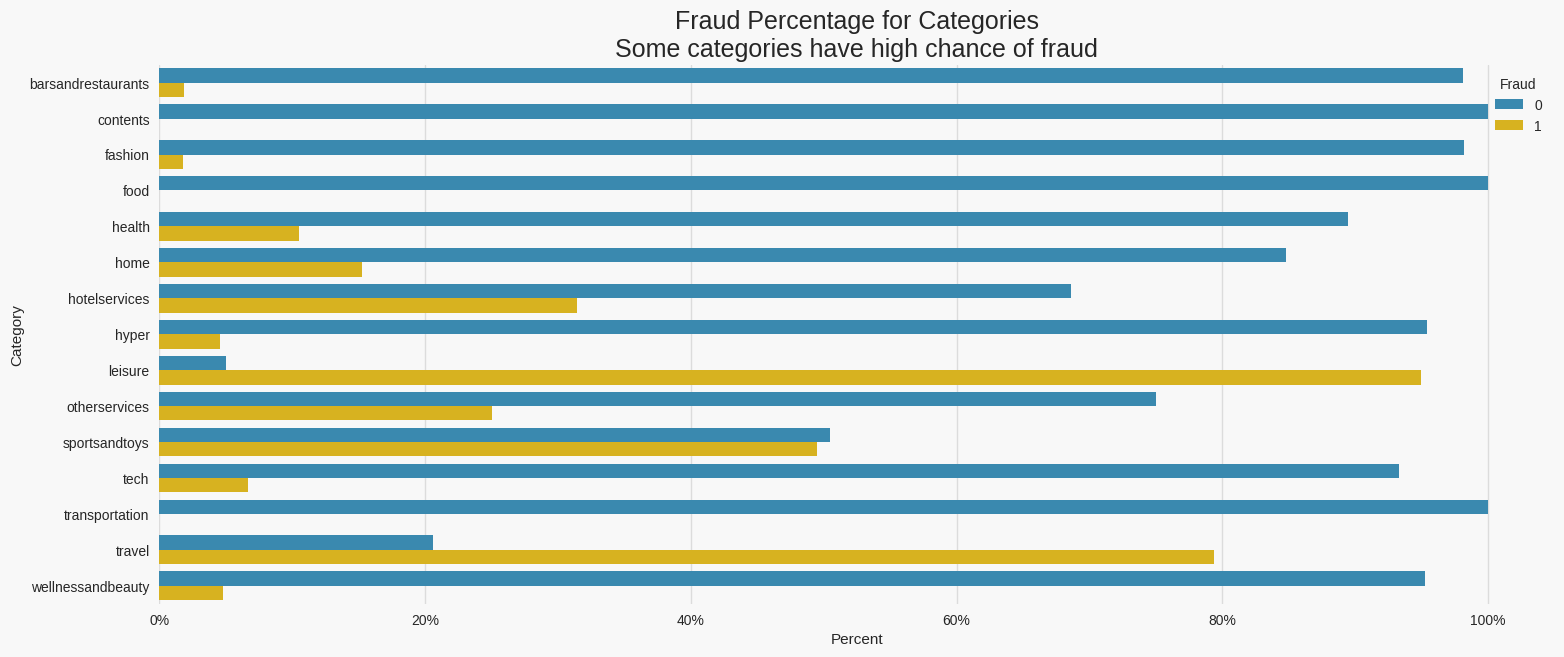

In [39]:
plt.figure(figsize=(18, 7))
category_fraud = data.groupby(['category', 'fraud']).size().unstack(fill_value=0)
category_fraud = category_fraud.div(category_fraud.sum(axis=1), axis=0)
category_fraud = category_fraud.reset_index().melt(id_vars='category', value_vars=[0, 1], var_name='fraud', value_name='percent')
sns.barplot(data=category_fraud, x='percent', y='category', hue='fraud', palette=colors_60s[3:5])
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
plt.title('Fraud Percentage for Categories\nSome categories have high chance of fraud', fontsize=18)
plt.xlabel('Percent')
plt.ylabel('Category')
plt.legend(title='Fraud')
plt.savefig('fraud_percentage_for_categs.png')
plt.show()

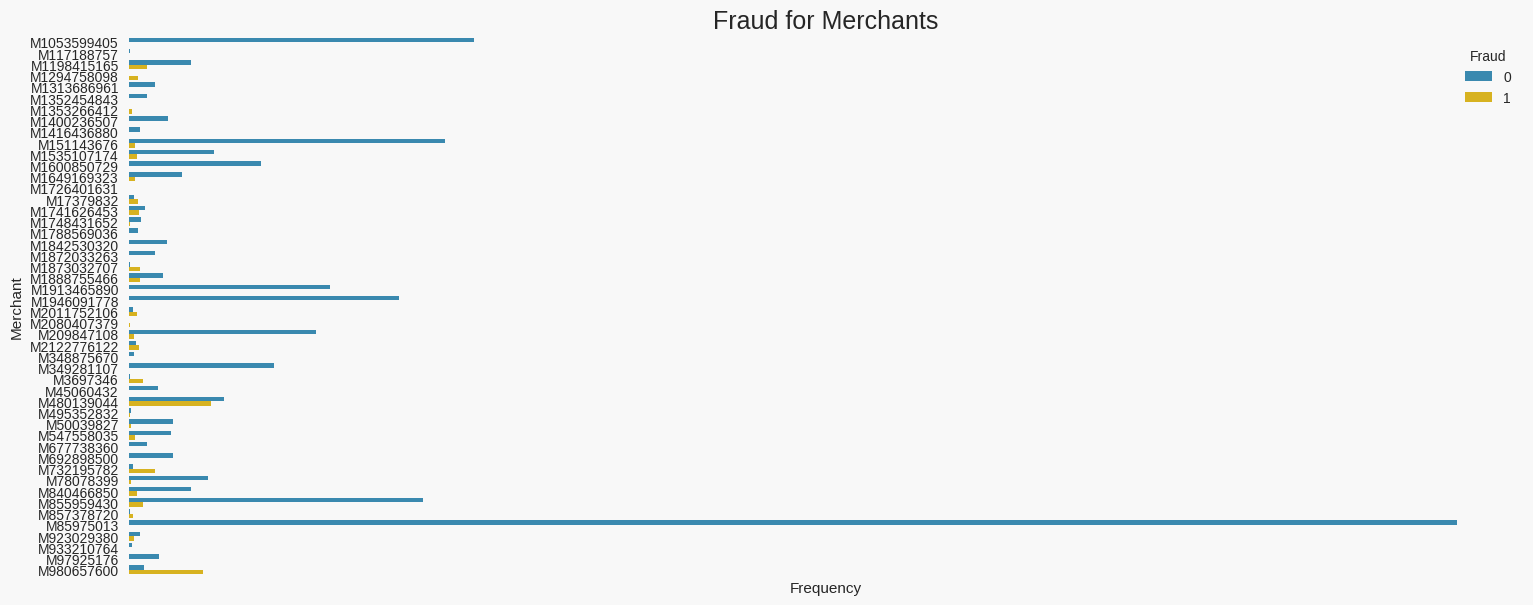

In [38]:
plt.figure(figsize=(18, 7))
merchant_fraud = data.groupby(['merchant', 'fraud']).size().unstack(fill_value=0).reset_index()
merchant_fraud = merchant_fraud[~merchant_fraud['merchant'].isin(['M1823072687', 'M348934600'])]
merchant_fraud = merchant_fraud.melt(id_vars='merchant', value_vars=[0, 1], var_name='fraud', value_name='n')
sns.barplot(data=merchant_fraud, x='n', y='merchant', hue='fraud', palette=colors_60s[3:5])
plt.title('Fraud for Merchants', fontsize=18)
plt.xlabel('Frequency')
plt.ylabel('Merchant')
plt.xticks([])
plt.legend(title='Fraud')
plt.savefig('fraud_for_merchants.png')
plt.show()